<a href="https://colab.research.google.com/github/VishnuCodes96/Rebounce-Applied-AI-and-Analytics-Codes/blob/main/MP5_StuntingRegression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Importing the libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression

## Loading & Understanding the data

In [2]:
from google.colab import files
uploaded = files.upload()

Saving mp5_nfhs5_district_health.csv to mp5_nfhs5_district_health (2).csv


In [3]:
df = pd.read_csv('mp5_nfhs5_district_health.csv')
df.head()

,state,district,stunted_children_pct,wasted_children_pct,underweight_children_pct,women_10yrs_school_pct,women_literate_pct,child_marriage_pct,improved_sanitation_pct,improved_water_pct,...,institutional_births_pct,full_vaccination_pct,anc_4visits_pct,health_insurance_pct,adequate_diet_pct,anaemic_children_pct,anaemic_women_pct,women_low_bmi_pct,teen_pregnancy_pct,is_aspirational
0,Andaman & Nicobar Islands,Nicobar,21.6,15.7,24.6,53.5,87.5,11.4,83.5,98.8,...,97.8,64.2,71.7,2.7,18.7,37.7,38.3,8.2,1.8,0
1,Andaman & Nicobar Islands,North & Middle Andaman,27.0,27.0,42.8,41.0,84.0,15.4,86.4,92.2,...,97.7,0.0,79.2,2.1,5.9,30.4,62.1,8.6,3.8,0
2,Andaman & Nicobar Islands,South Andaman,21.1,12.6,17.4,57.5,86.7,17.1,89.3,97.9,...,99.5,76.3,85.9,1.2,23.5,43.4,57.7,10.0,2.8,0
3,Andhra Pradesh,Anantapur,36.0,19.3,40.6,31.3,63.6,37.3,71.3,98.8,...,94.7,81.8,66.6,73.2,2.9,55.8,50.5,21.9,13.6,0
4,Andhra Pradesh,Chittoor,27.1,14.8,27.9,40.3,69.3,28.1,74.6,98.5,...,97.1,66.6,65.3,70.7,6.0,54.9,51.8,20.1,19.7,0


In [4]:
print(f'No. of Rows & Columns: {df.shape}')
print("==" * 30)
print("DATA OVERVIEW")
print("==" * 30)
print(df.info())

No. of Rows & Columns: (707, 22)
DATA OVERVIEW
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 707 entries, 0 to 706
Data columns (total 22 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   state                     707 non-null    object 
 1   district                  707 non-null    object 
 2   stunted_children_pct      707 non-null    float64
 3   wasted_children_pct       707 non-null    float64
 4   underweight_children_pct  707 non-null    float64
 5   women_10yrs_school_pct    707 non-null    float64
 6   women_literate_pct        707 non-null    float64
 7   child_marriage_pct        707 non-null    float64
 8   improved_sanitation_pct   707 non-null    float64
 9   improved_water_pct        707 non-null    float64
 10  clean_cooking_fuel_pct    707 non-null    float64
 11  electricity_pct           707 non-null    float64
 12  institutional_births_pct  707 non-null    float64
 13  full_vaccination_p

In [5]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
stunted_children_pct,707.0,33.463791,8.558704,0.0,27.30,32.8,39.20,60.6
wasted_children_pct,707.0,18.511881,6.515121,0.0,13.90,18.1,22.75,48.0
underweight_children_pct,707.0,29.460113,9.738311,0.0,22.05,29.3,36.20,62.4
women_10yrs_school_pct,707.0,40.267185,14.308171,0.0,28.95,39.2,49.90,88.2
women_literate_pct,707.0,72.984017,13.007541,0.0,64.40,73.8,82.90,99.7
child_marriage_pct,707.0,20.637058,12.802683,0.0,10.85,18.3,28.20,80.9
improved_sanitation_pct,707.0,71.843989,14.541987,0.0,62.00,73.7,83.30,99.9
improved_water_pct,707.0,93.646959,9.348504,0.0,92.05,97.0,99.30,100.0
clean_cooking_fuel_pct,707.0,54.092221,24.275144,0.0,33.95,50.4,75.35,99.8
electricity_pct,707.0,96.868883,5.676925,0.0,96.40,98.7,99.50,100.0


### Key observations:
1. 0% filled the `min` column which looks impossible.
2. `teen_pregnancy_pct` has a max value of 91.9% which seems unusually high compared to 75th percentile which has value of 8.65%

### Counting how many zeros each column has

In [6]:
# Count the number of zeros in each column
zero_counts = (df == 0).sum()

# Display the results
print(zero_counts.sort_values(ascending=False))

is_aspirational             595
teen_pregnancy_pct           18
full_vaccination_pct         14
adequate_diet_pct             7
child_marriage_pct            2
wasted_children_pct           1
institutional_births_pct      1
electricity_pct               1
women_10yrs_school_pct        1
underweight_children_pct      1
stunted_children_pct          1
improved_water_pct            1
improved_sanitation_pct       1
women_literate_pct            1
anaemic_children_pct          1
health_insurance_pct          1
clean_cooking_fuel_pct        1
anc_4visits_pct               1
women_low_bmi_pct             1
anaemic_women_pct             1
state                         0
district                      0
dtype: int64


### Finding the row named "Data Not Available".

In [7]:
df[df['district'] == 'Data Not Available']

,state,district,stunted_children_pct,wasted_children_pct,underweight_children_pct,women_10yrs_school_pct,women_literate_pct,child_marriage_pct,improved_sanitation_pct,improved_water_pct,...,institutional_births_pct,full_vaccination_pct,anc_4visits_pct,health_insurance_pct,adequate_diet_pct,anaemic_children_pct,anaemic_women_pct,women_low_bmi_pct,teen_pregnancy_pct,is_aspirational
211,Jammu & Kashmir,Data Not Available,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0


### Key Observation:
I will clean the row named "Data Not Available" from the dataset because it contains zero values across all numerical indicators, which likely represent missing data rather than actual district-level measurements. Keeping this row could distort the statistical analysis and negatively affect the accuracy of our linear regression model.

## Cleaning the Data

In [8]:
df = df[df['district'] != 'Data Not Available'] # Removing the "Data Not Available" row
df.shape # 707 rows - 1 = 706 rows

(706, 22)

In [9]:
# Identify percentage columns
percentage_cols = df.columns[df.columns.str.endswith('_pct')]

# Replace 0 with NaN in percentage columns
df[percentage_cols] = df[percentage_cols].replace(0, np.nan)

In [10]:
df['teen_pregnancy_pct'].sort_values(ascending=False).head(5)

,teen_pregnancy_pct
107,91.9
297,80.3
694,27.3
591,26.9
595,26.6


### Key Observations:
The highest two values (91.9% and 80.3%) appear unusually high compared with the remaining observations and may indicate data quality issues. Therefore, I will exclude this column from the model features.

In [11]:
# Print dataset shape
print("Dataset shape:", df.shape)

# Print missing-value count for each column
print("\nMissing values per column:")
print(df.isnull().sum())

Dataset shape: (706, 22)

Missing values per column:
state                        0
district                     0
stunted_children_pct         0
wasted_children_pct          0
underweight_children_pct     0
women_10yrs_school_pct       0
women_literate_pct           0
child_marriage_pct           1
improved_sanitation_pct      0
improved_water_pct           0
clean_cooking_fuel_pct       0
electricity_pct              0
institutional_births_pct     0
full_vaccination_pct        13
anc_4visits_pct              0
health_insurance_pct         0
adequate_diet_pct            6
anaemic_children_pct         0
anaemic_women_pct            0
women_low_bmi_pct            0
teen_pregnancy_pct          17
is_aspirational              0
dtype: int64


### Visualising Stunted Children Percentage

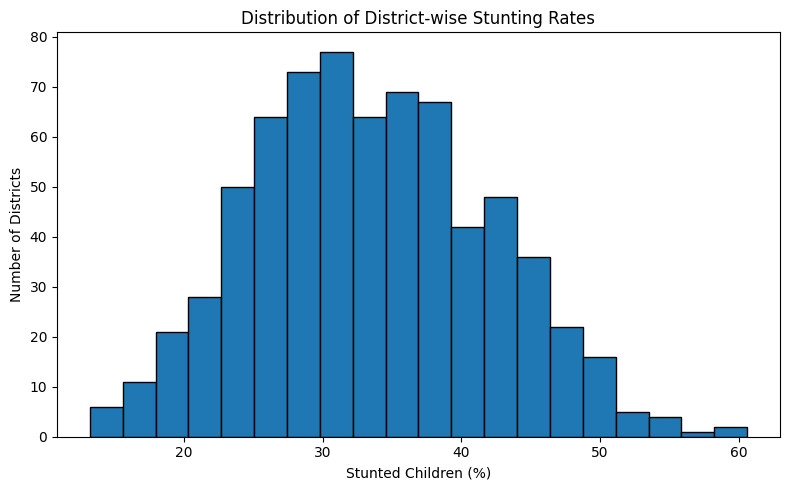

In [12]:
plt.figure(figsize=(8, 5))

plt.hist(df['stunted_children_pct'], bins=20, edgecolor='black')

plt.xlabel('Stunted Children (%)')
plt.ylabel('Number of Districts')
plt.title('Distribution of District-wise Stunting Rates')
plt.tight_layout()
plt.show()

### Key Observations:
1. What is the typical district?

* Most districts have a stunting rate between 25% and 40%, with the highest concentration around 30–32%. Therefore, a typical district has approximately 30–35% of children classified as stunted.

2. Is the shape skewed?

* The distribution is slightly positively (right) skewed. Most districts are concentrated around 25–40%, while a smaller number of districts extend towards higher stunting rates (50–60%), creating a longer tail on the right.

### Calculating correlation of every column with stunting

In [13]:
correlation = df.select_dtypes(include='number').corr()['stunted_children_pct'].sort_values(ascending=False)
print(correlation)

stunted_children_pct        1.000000
underweight_children_pct    0.701788
women_low_bmi_pct           0.552092
child_marriage_pct          0.426367
anaemic_children_pct        0.331509
is_aspirational             0.298902
wasted_children_pct         0.238255
anaemic_women_pct           0.238045
teen_pregnancy_pct          0.146764
improved_water_pct         -0.037207
health_insurance_pct       -0.121148
full_vaccination_pct       -0.195079
adequate_diet_pct          -0.234880
anc_4visits_pct            -0.360826
institutional_births_pct   -0.380700
clean_cooking_fuel_pct     -0.412485
electricity_pct            -0.427657
improved_sanitation_pct    -0.502898
women_literate_pct         -0.538993
women_10yrs_school_pct     -0.540876
Name: stunted_children_pct, dtype: float64


### Strongest positive correlation
| Variable | Correlation | Interpretation |
| --- | --- | --- |
| underweight_children_pct | +0.702	| Strong positive relationship |
| women_low_bmi_pct |	+0.552	| Moderate positive relationship |
| child_marriage_pct |	+0.426 |	Moderate positive relationship |
| anaemic_children_pct |	+0.332 |	Weak-to-moderate positive relationship |

Districts with higher proportions of underweight children and women with low BMI tend to have higher stunting rates.

### Strongest negative correlations
| Variable | Correlation | Interpretation |
| --- | --- | --- |
| women_10yrs_school_pct | -0.541	| Moderate negative relationship |
| women_literate_pct | -0.539 | Moderate negative relationship |
| improved_sanitation_pct | -0.503 |  Moderate negative relationship |

Districts with higher female literacy, education and improved sanitation tend to have lower child stunting rates.

### Interesting Patterns:
1. **Nutritional indicators**: Underweight children have the strongest positive correlation with stunting (+0.702). This suggests that the two nutritional outcomes frequently occur together.
2. **Women's education**: Female education has a negative correlation with stunting (-0.541), suggesting that districts with better female education tend to have lower stunting rates.
3. **Living conditions**: Improved sanitation (-0.503) and electricity (-0.428) also show negative associations with stunting.

* These are correlations, not evidence of causation. We cannot conclude that improving one indicator will automatically reduce stunting.